<a href="https://colab.research.google.com/github/ashoka-1967/my-first-repository/blob/QFF-2026-Hackathon/SQD_noise_sampling_experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# If you are on Google Colab or a fresh environment, uncomment and run:
%pip install "numpy>=2.3.2" "qiskit==2.5.2" "qiskit-aer==0.17.2" \
"qiskit-addon-sqd==0.12.1" "ffsim>=0.0.81" "pyscf==2.14.0" \
"matplotlib==3.11.1" "pylatexenc==2.10"

from collections import Counter
from math import comb

import numpy as np
import matplotlib.pyplot as plt
import pyscf
import pyscf.ao2mo
import pyscf.cc
import pyscf.mcscf
import ffsim
from qiskit import QuantumCircuit
from qiskit.primitives import BitArray
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_addon_sqd.fermion import diagonalize_fermionic_hamiltonian

rng = np.random.default_rng(2026)

In [3]:
def build_active_space_problem(atom, basis="sto-3g", n_frozen=0, compare_to_fci=True):
    """Build a small closed-shell active-space chemistry problem."""
    mol = pyscf.gto.Mole()
    mol.build(atom=atom, basis=basis, verbose=0)
    assert mol.nelectron % 2 == 0, "this teaching helper expects a closed-shell molecule"

    scf = pyscf.scf.RHF(mol).run()
    active_orbitals = list(range(n_frozen, mol.nao_nr()))
    norb = len(active_orbitals)
    n_active_electrons = int(round(np.sum(scf.mo_occ[active_orbitals])))
    n_alpha = (n_active_electrons + mol.spin) // 2
    n_beta = (n_active_electrons - mol.spin) // 2
    nelec = (n_alpha, n_beta)

    # CASCI is used here only as a convenient active-space integral transformer.
    cas = pyscf.mcscf.CASCI(scf, norb, nelec)
    mo = cas.sort_mo(active_orbitals, base=0)
    hcore, e_core = cas.get_h1cas(mo)
    eri = pyscf.ao2mo.restore(1, cas.get_h2cas(mo), norb)

    frozen = [index for index in range(mol.nao_nr()) if index not in active_orbitals] or None
    ccsd = pyscf.cc.CCSD(scf, frozen=frozen).run()
    e_fci = cas.kernel(mo)[0] if compare_to_fci else None

    return {
        "atom": atom,
        "basis": basis,
        "n_frozen": n_frozen,
        "mol": mol,
        "scf": scf,
        "ccsd": ccsd,
        "norb": norb,
        "nelec": nelec,
        "hcore": hcore,
        "eri": eri,
        "e_core": e_core,
        "e_hf": scf.e_tot,
        "e_ccsd": ccsd.e_tot,
        "e_fci": e_fci,
    }


def print_problem_summary(problem):
    print(f"active orbitals: {problem['norb']} | electrons: {problem['nelec']} | "
          f"qubits: {2 * problem['norb']}")
    if problem["e_fci"] is not None:
        reference = problem["e_fci"]
        print(f"Hartree-Fock : {problem['e_hf']:.6f} Ha | error {(problem['e_hf'] - reference) * 1000:+8.2f} mHa")
        print(f"CCSD         : {problem['e_ccsd']:.6f} Ha | error {(problem['e_ccsd'] - reference) * 1000:+8.2f} mHa")
        print(f"exact (FCI)  : {reference:.6f} Ha")
    else:
        print(f"Hartree-Fock : {problem['e_hf']:.6f} Ha")
        print(f"CCSD         : {problem['e_ccsd']:.6f} Ha")


bond = 1.5
n2_atom = [["N", (0, 0, 0)], ["N", (bond, 0, 0)]]
problem = build_active_space_problem(n2_atom, basis="sto-3g", n_frozen=2, compare_to_fci=True)
print_problem_summary(problem)

norb = problem["norb"]
nelec = problem["nelec"]
n_alpha, n_beta = nelec
hcore, eri, e_core = problem["hcore"], problem["eri"], problem["e_core"]
e_hf, e_ccsd, e_fci = problem["e_hf"], problem["e_ccsd"], problem["e_fci"]

active orbitals: 8 | electrons: (5, 5) | qubits: 16
Hartree-Fock : -107.272449 Ha | error  +309.03 mHa
CCSD         : -107.567708 Ha | error   +13.77 mHa
exact (FCI)  : -107.581483 Ha


In [4]:
def run_sqd(
    atom,
    *,
    basis="sto-3g",
    n_frozen=0,
    n_reps=2,
    shots=20_000,
    noise_p=0.02,
    samples_per_batch=500,
    num_batches=3,
    max_iterations=6,
    symmetrize_spin=False,
    seed=2026,
    compare_to_fci=True,
):
    """Coordinate the four teaching-stage helpers for a small closed-shell molecule."""
    problem = build_active_space_problem(
        atom, basis=basis, n_frozen=n_frozen, compare_to_fci=compare_to_fci
    )
    print_problem_summary(problem)
    circuit = build_ansatz(problem, n_reps=n_reps, measure=True)
    samples = sample_circuit(circuit, shots=shots, seed=seed)

    solve_samples = samples["bit_array"]
    noisy_bools = None
    if noise_p:
        solve_samples, noisy_bools = add_bit_flip_noise(solve_samples, noise_p, seed=seed + 1)

    sqd = recover_and_diagonalize(
        problem,
        solve_samples,
        label="run_sqd",
        samples_per_batch=samples_per_batch,
        num_batches=num_batches,
        max_iterations=max_iterations,
        symmetrize_spin=symmetrize_spin,
        seed=seed + 2,
    )
    return {
        "problem": problem,
        "circuit": circuit,
        "samples": samples,
        "noisy_bools": noisy_bools,
        "sqd": sqd,
    }

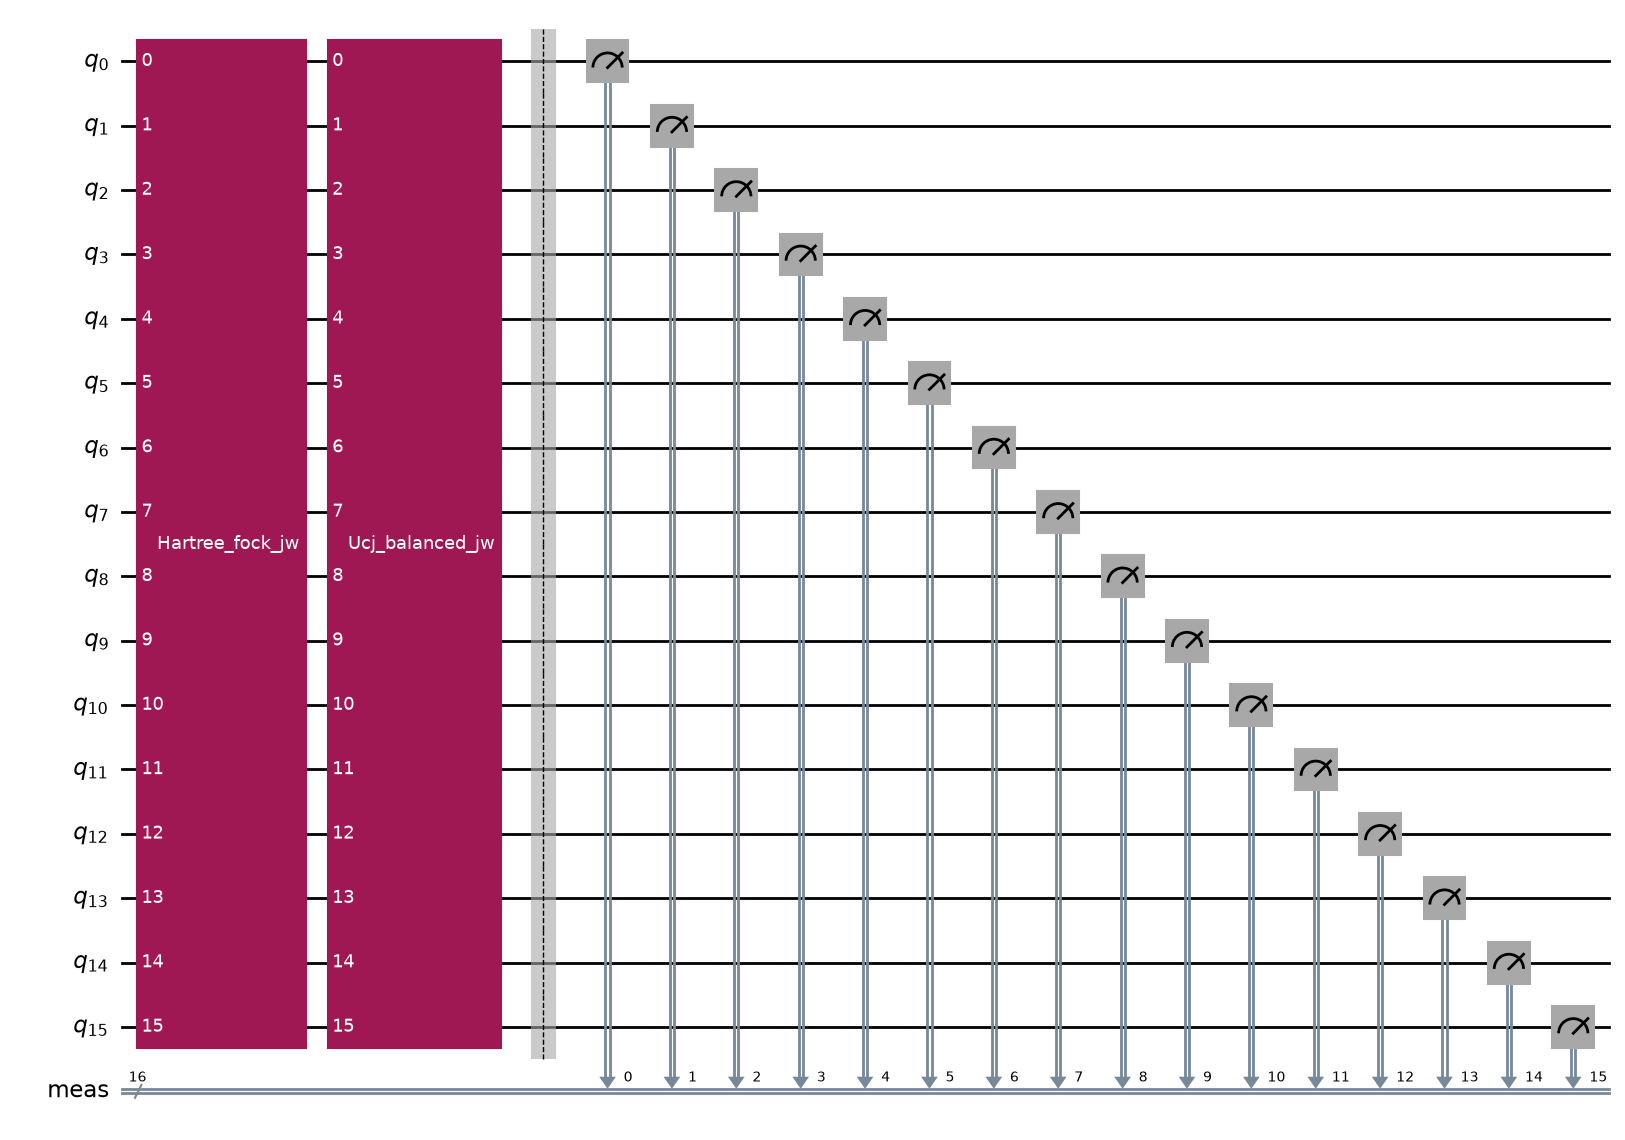

In [7]:
def build_ansatz(problem, n_reps=2, measure=True):
    """Build a spin-balanced UCJ ansatz initialized from the problem's CCSD amplitudes."""
    norb = problem["norb"]
    nelec = problem["nelec"]
    ccsd = problem["ccsd"]

    ucj_op = ffsim.UCJOpSpinBalanced.from_t_amplitudes(
        t2=ccsd.t2,
        t1=ccsd.t1,
        n_reps=n_reps,
    )
    circuit = QuantumCircuit(2 * norb)
    circuit.append(ffsim.qiskit.PrepareHartreeFockJW(norb, nelec), circuit.qubits)
    circuit.append(ffsim.qiskit.UCJOpSpinBalancedJW(ucj_op), circuit.qubits)
    if measure:
        circuit.measure_all()
    return circuit


circuit = build_ansatz(problem, n_reps=2, measure=True)
circuit.draw("mpl", fold=-1)

In [10]:
def sample_circuit(circuit, shots=20_000, seed=123, optimization_level=1):
    """Compile and sample a measured circuit on Aer."""
    backend = AerSimulator()
    pass_manager = generate_preset_pass_manager(
        optimization_level=optimization_level,
        backend=backend,
    )
    isa_circuit = pass_manager.run(circuit)
    two_qubit_gates = sum(
        1 for instruction in isa_circuit.data if instruction.operation.num_qubits == 2
    )
    bit_array = (
        SamplerV2(seed=seed)
        .run([isa_circuit], shots=shots)
        .result()[0]
        .data.meas
    )
    strings = bit_array.get_bitstrings()
    return {
        "backend": backend,
        "isa_circuit": isa_circuit,
        "bit_array": bit_array,
        "strings": strings,
        "shots": shots,
        "depth": isa_circuit.depth(),
        "two_qubit_gates": two_qubit_gates,
    }


sample_record = sample_circuit(circuit, shots=20_000, seed=123)
bit_array = sample_record["bit_array"]
strings = sample_record["strings"]
shots = sample_record["shots"]

print(f"compiled circuit: depth {sample_record['depth']}, "
      f"{sample_record['two_qubit_gates']} two-qubit gates")
print(f"{bit_array.num_shots:,} shots x {bit_array.num_bits} bits, "
      f"{len(set(strings)):,} distinct sampled rows")

compiled circuit: depth 156, 604 two-qubit gates
20,000 shots x 16 bits, 115 distinct sampled rows


In [13]:
def recover_and_diagonalize(
    problem,
    bit_array,
    *,
    label,
    samples_per_batch=500,
    num_batches=3,
    max_iterations=6,
    symmetrize_spin=False,
    seed=31415,
    verbose=True,
):
    """Run SQD and return a transparent record of energies and subspace dimensions."""
    history = []

    def callback(results):
        best = min(results, key=lambda result: result.energy)
        batch_shapes = [tuple(int(x) for x in result.sci_state.amplitudes.shape) for result in results]
        batch_dimensions = [int(np.prod(shape)) for shape in batch_shapes]
        total_energy = best.energy + problem["e_core"]
        history.append({
            "energy": total_energy,
            "batch_shapes": batch_shapes,
            "batch_dimensions": batch_dimensions,
        })
        if verbose:
            reference_text = ""
            if problem["e_fci"] is not None:
                reference_text = f" | error {(total_energy - problem['e_fci']) * 1000:+7.2f} mHa"
            print(f"  {label}, iteration {len(history)}: E = {total_energy:.6f} Ha{reference_text} "
                  f"| batch dimensions {batch_dimensions}")

    result = diagonalize_fermionic_hamiltonian(
        problem["hcore"],
        problem["eri"],
        bit_array,
        samples_per_batch=samples_per_batch,
        norb=problem["norb"],
        nelec=problem["nelec"],
        num_batches=num_batches,
        energy_tol=0.0,
        occupancies_tol=0.0,
        max_iterations=max_iterations,
        symmetrize_spin=symmetrize_spin,
        callback=callback,
        seed=seed,
    )

    energy = result.energy + problem["e_core"]
    final_shape = tuple(int(x) for x in result.sci_state.amplitudes.shape)
    strings = bit_array.get_bitstrings()
    error_mha = None if problem["e_fci"] is None else (energy - problem["e_fci"]) * 1000
    return {
        "label": label,
        "result": result,
        "energy": energy,
        "error_mha": error_mha,
        "history": history,
        "distinct_sample_rows": len(set(strings)),
        "final_shape": final_shape,
        "final_dimension": int(np.prod(final_shape)),
        "settings": {
            "samples_per_batch": samples_per_batch,
            "num_batches": num_batches,
            "max_iterations": max_iterations,
            "symmetrize_spin": symmetrize_spin,
            "seed": seed,
        },
    }

In [14]:
# Stretch water's O-H bond
water_stretched = [["O", (0.0, 0.0, 0.1173)],
                   ["H", (0.0, 0.9086, -0.4692)],
                   ["H", (0.0, -0.9086, -0.4692)]]

In [24]:
from qiskit.primitives import BitArray
import qiskit
print(qiskit.__version__)

import qiskit.primitives
print(dir(qiskit.primitives))

2.5.2
['BackendEstimatorV2', 'BackendSamplerV2', 'BaseEstimatorV1', 'BaseEstimatorV2', 'BasePrimitiveJob', 'BaseSamplerV1', 'BaseSamplerV2', 'BindingsArray', 'BindingsArrayLike', 'BitArray', 'DataBin', 'EstimatorPub', 'EstimatorPubLike', 'EstimatorResult', 'ObservableLike', 'ObservablesArray', 'ObservablesArrayLike', 'ParameterLike', 'PrimitiveJob', 'PrimitiveResult', 'PubResult', 'SamplerPub', 'SamplerPubLike', 'SamplerPubResult', 'SamplerResult', 'StatevectorEstimator', 'StatevectorSampler', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', 'backend_estimator_v2', 'backend_sampler_v2', 'base', 'containers', 'make_data_bin', 'primitive_job', 'statevector_estimator', 'statevector_sampler', 'utils']


In [25]:
import numpy as np
from qiskit.primitives import BitArray

def add_bit_flip_noise(bit_array, probability, seed=2026):
    clean = bitstrings_to_bool(bit_array.get_bitstrings())

    local_rng = np.random.default_rng(seed)

    noisy = clean ^ (local_rng.random(clean.shape) < probability)

    return BitArray.from_bool_array(noisy, order="big"), noisy

In [27]:
def bitstrings_to_bool(strings):
    return np.asarray([[character == "1" for character in string] for string in strings], dtype=bool)


def valid_electron_counts(bitstrings, norb, nelec):
    """Mask rows with the target alpha count on the right and beta count on the left."""
    bitstrings = np.asarray(bitstrings, dtype=bool)
    alpha_ok = bitstrings[:, norb:].sum(axis=1) == nelec[0]
    beta_ok = bitstrings[:, :norb].sum(axis=1) == nelec[1]
    return alpha_ok & beta_ok


def pretty(s):
    return s[:norb] + "·" + s[norb:]


bools_clean = bitstrings_to_bool(strings)
clean_valid = valid_electron_counts(bools_clean, norb, nelec)
assert clean_valid.all(), "the noiseless number-conserving ansatz should return only valid rows"
print(f"valid electron counts: {clean_valid.mean():.0%}")

valid electron counts: 100%


In [28]:
import pandas as pd
import numpy as np

noise_levels = [0, 0.02, 0.05, 0.10, 0.15]
shots_list = [1000, 5000, 10000, 20000]

results = []

for noise in noise_levels:
    for shots in shots_list:

        print(f"Running: noise={noise:.2f}, shots={shots}")

        result = run_sqd(
            atom=water_stretched,
            n_frozen=1,
            n_reps=2,
            shots=shots,
            noise_p=noise,
            samples_per_batch=500,
            num_batches=3,
            max_iterations=6,
            symmetrize_spin=False,
            seed=2026,
            compare_to_fci=False
        )

        sqd_result = result["sqd"]

        results.append({
            "noise": noise,
            "shots": shots,
            "energy": sqd_result["energy"],
            "final_dimension": sqd_result["final_dimension"],
            "final_shape": sqd_result["final_shape"]
        })

df = pd.DataFrame(results)

df

Running: noise=0.00, shots=1000
active orbitals: 6 | electrons: (4, 4) | qubits: 12
Hartree-Fock : -74.939140 Ha
CCSD         : -75.005221 Ha
  run_sqd, iteration 1: E = -74.988163 Ha | batch dimensions [36, 36, 36]
  run_sqd, iteration 2: E = -74.988163 Ha | batch dimensions [36, 36, 36]
  run_sqd, iteration 3: E = -74.988163 Ha | batch dimensions [36, 36, 36]
  run_sqd, iteration 4: E = -74.988163 Ha | batch dimensions [36, 36, 36]
  run_sqd, iteration 5: E = -74.988163 Ha | batch dimensions [36, 36, 36]
  run_sqd, iteration 6: E = -74.988163 Ha | batch dimensions [36, 36, 36]
Running: noise=0.00, shots=5000
active orbitals: 6 | electrons: (4, 4) | qubits: 12
Hartree-Fock : -74.939140 Ha
CCSD         : -75.005221 Ha
  run_sqd, iteration 1: E = -74.988163 Ha | batch dimensions [36, 36, 36]
  run_sqd, iteration 2: E = -74.988163 Ha | batch dimensions [36, 36, 36]
  run_sqd, iteration 3: E = -74.988163 Ha | batch dimensions [36, 36, 36]
  run_sqd, iteration 4: E = -74.988163 Ha | batch 

,noise,shots,energy,final_dimension,final_shape
0,0.00,1000,-74.988163,36,"(6, 6)"
1,0.00,5000,-74.988163,36,"(6, 6)"
2,0.00,10000,-74.988163,36,"(6, 6)"
3,0.00,20000,-74.988163,36,"(6, 6)"
4,0.02,1000,-74.995422,70,"(7, 10)"
5,0.02,5000,-75.004730,143,"(13, 11)"
6,0.02,10000,-75.005454,196,"(14, 14)"
7,0.02,20000,-75.005465,210,"(15, 14)"
8,0.05,1000,-75.005334,143,"(11, 13)"
9,0.05,5000,-75.005454,182,"(14, 13)"


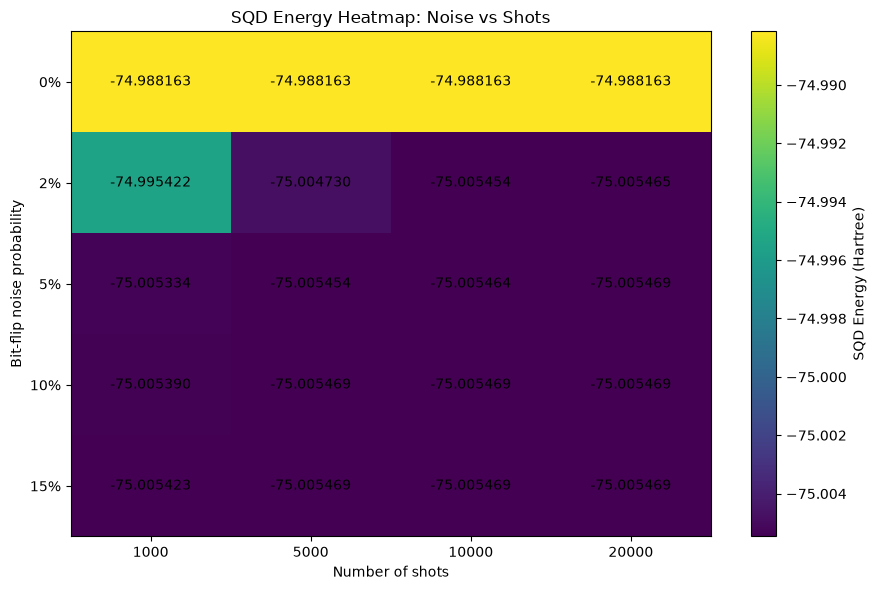

In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Pivot table: rows = noise, columns = shots
energy_pivot = df.pivot(
    index="noise",
    columns="shots",
    values="energy"
)

fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(energy_pivot.values, aspect="auto")

ax.set_xticks(range(len(energy_pivot.columns)))
ax.set_xticklabels(energy_pivot.columns)

ax.set_yticks(range(len(energy_pivot.index)))
ax.set_yticklabels([f"{n:.0%}" for n in energy_pivot.index])

ax.set_xlabel("Number of shots")
ax.set_ylabel("Bit-flip noise probability")
ax.set_title("SQD Energy Heatmap: Noise vs Shots")

for i in range(energy_pivot.shape[0]):
    for j in range(energy_pivot.shape[1]):
        ax.text(
            j, i,
            f"{energy_pivot.iloc[i, j]:.6f}",
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax, label="SQD Energy (Hartree)")
plt.tight_layout()
plt.show()


The SQD energy heatmap exhibits a non-monotonic dependence on the applied classical bit-flip noise and the sampling budget. In the noiseless case, the computed energy remains unchanged across all shot counts and is noticeably higher than the energies obtained under nonzero noise. At 2% noise, the energy improves significantly with increasing shots, approaching a stable value near −75.005465 Hartree. For noise levels of 5%, 10%, and 15%, the computed energy exhibits pronounced saturation, with minimal variation across the tested shot counts. These observations suggest that the configuration-recovery and subspace-diagonalization pipeline may be robust to the introduced post-sampling perturbations under these experimental settings. Nevertheless, the apparent advantage of nonzero noise should not be interpreted as a causal improvement in SQD performance until the sampled configuration pools, recovered subspace dimensions, validity rates, and benchmark errors are systematically compared.
